# Title

**Exercise 2 [Not Graded!] - A Walkthrough Example**

# Description

The aim of this exercise is to let you do some analysis on your own with less structure.

# Dataset Description:
The dataset used here is the Wine data set (another commonly used sklearn dataset).  Use this to answer the questions embedded in the Notebook.

# Instructions:
1. Read the data.  
2. Do some explorations.
3. Fit some multiclass models.
4. Interpret these models.

# Hints:

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html" target="_blank">sklearn.LogisticRegression()</a> : Generates a Logistic Regression classifier

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.fit" target="_blank">sklearn.fit()</a> : Fits the model to the given data

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.predict" target="_blank">sklearn.predict()</a> : Predict using the estimated model (Logistic or knn classifiers) to perform pure classification predictions

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.predict_proba" target="_blank">sklearn.predict_proba()</a> : Predict using the estimated model (Logistic or knn classifiers) to perform probability predictions of all the classes in the response (they should add up to 1 for each observation)

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html" target="_blank">sklearn.LogisticRegression.coef_ and .intercept_</a> : Pull off the estimated β coefficients in a Logistic Regression model

<a href="https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html" target="_blank">sklearn.KNeighborsClassifier</a> : Fit a k-NN classification model

Note: This exercise is NOT auto-graded.

In [152]:
%matplotlib inline
from sklearn import datasets
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from math import exp


from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier 
#import sklearn.metrics as met

from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

First Read in the data set and take a peak at it:

In [153]:
raw = datasets.load_wine()

df = pd.DataFrame(raw.data, columns=raw.feature_names)
df['wine_type'] = raw.target

X_full = pd.DataFrame(raw['data'],columns=raw['feature_names'])
y = raw['target']
print(X_full.shape,y.shape)

(178, 13) (178,)


In [154]:
X_full.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


**Q1**: Perform a 70-30 `train_test_split` using `random_state=109` and `shuffle=True`.  Why is it important to shuffle here?

In [155]:
X_train, y_train, X_test, y_test = train_test_split(X_full, y, random_state=109, shuffle=True)

**Q2**: Explore the data a little.  Visualize the marginal association (aka, bivariate relationship) of wine type to amount of alcohol, level of malic acid, and total level of phenols.  Which predictor seems to have the strongest association with the response?

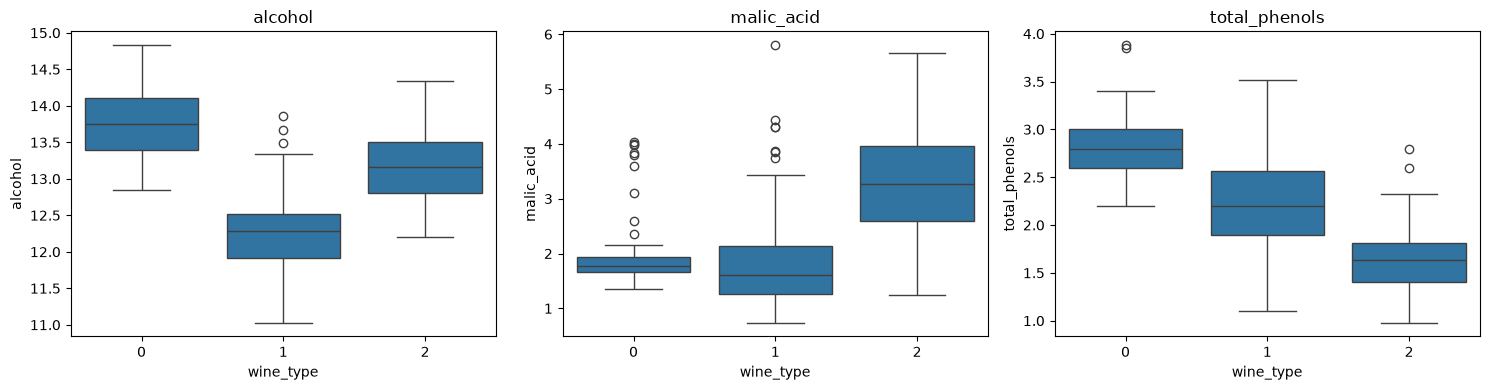

In [156]:
### your code here

features = ['alcohol', 'malic_acid', 'total_phenols']

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, feature in enumerate(features):
    sns.boxplot(data=df, x='wine_type', y=feature, ax=axes[i])
    axes[i].set_title(feature)

plt.tight_layout()
plt.show()

total_phenols, it clearly separates type 2 = less phenols; type 1 = intermidiate phenols; and type 0 = more phenols

**Q3**: Fit 3 different models with ['alcohol','malic_acid'] as the predictors: (1) a standard logistic regression to predict a binary indicator for class 0 (you'll have to crete it yourself), (2) a multinomial logistic regression to predict all 3 classes and (3) a OvR logistic reression to predict all 3 classes.  Compare the results

In [157]:
###your code here

x = df[['alcohol', 'malic_acid']]
y_0 = (df['wine_type'] == 0).astype(int)

logit_stand = LogisticRegression()
logit_stand.fit(x, y_0)

beta0 = logit_stand.intercept_[0]
beta1, beta2 = logit_stand.coef_[0]

logit = []

for alcohol, malic_acid in zip(x['alcohol'], x['malic_acid']):
    p = 1 / (1 + exp(-(beta0 + beta1 * alcohol + beta2 * malic_acid)))
    logit.append(p)

y_pred = []

for py in logit:
    if py >= 0.5:
        y_pred.append(1)
    else:
        y_pred.append(0)

stand_accuracy = logit_stand.score(x, y_0)


# Multi 
logit_multi = LogisticRegression(multi_class='multinomial',max_iter = 1000).fit(x, y)
intercept = logit_multi.intercept_
coefs = logit_multi.coef_

multi_accuracy = logit_multi.score(x, y)


# OVR
logit_ovr = LogisticRegression(multi_class='ovr',max_iter = 1000).fit(x, y)


ovr_accuracy = logit_ovr.score(x, y)

# Print the accuracy
print("Standard: ",stand_accuracy)
print("Multi: ", multi_accuracy)
print("OVR: ", ovr_accuracy)
    

Standard:  0.8595505617977528
Multi:  0.7752808988764045
OVR:  0.7808988764044944


*your answer here*

**Q4**: For the Multinomial model, use the estimated coefficients to calculate the predicted probabilties by hand.  Feel free to confirm with the `predict_proba` command.

In [158]:
### your code here


*your answer here*

**Q5**: For the OvR model, use the `predict_proba()` to estimate the predicted probabilities in the test set, and manually use this to calculate the predicted classes.  Feel free to confirm with the `predict` command.

In [159]:
### your code here


**Q6**: How could you use the `predict_proba()` command and 'change the threshold' in the multiclass setting to affect predictive accuracies within each class?  Note: it is not as simple as changing a threshold because there is not threshold

*your answer here*

**Q7**: Compare the accuracies in both train and test for both the multinomial and OvR logistic regressions.  Which seems to be performing better?  Is there any evidence of overfitting?  How could this be corrected?

In [160]:
### your code here

*your answer here*

**Q8**: Create the classification boundaries for the two multiclass logistic regression models above.  How do they compare?

In [161]:
###your code here



*your answer here*

**Q9**: Fit 3 different knn regression models: for $k = 3, 10, 30$. Visualize the classification boundaries for these 3 models and compare the results.  Which seem to be overfit?

In [162]:
### your answer here

In [163]:
### your answer here

*your answer here*

**Q10** How could you visualize the classification boundary for any of these models if there was a single predictor?  What if there were more than 2 predictors?

*your answer here*